In [2]:
import pandas as pd 
import numpy as np

In [3]:
df = pd.read_csv('placement.csv')

In [4]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [5]:
df.shape

(100, 4)

In [6]:
# Steps

# 0. Preprocess + EDA + Feature Selection
# 1. Extract input and output cols
# 2. Scale the values
# 3. Train test split
# 4. Train the model
# 5. Evaluate the model/model selection
# 6. Deploy the model

# starting with : Preprocessing 

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [8]:
# there is no noise in data , So we will just be removing unnamed col-1 --> its useless

df.iloc[ : , 1 : ]

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0
...,...,...,...
95,4.3,200.0,0
96,4.4,42.0,0
97,6.7,182.0,1
98,6.3,103.0,1


In [9]:
df = df.iloc[ : , 1 : ]

In [10]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


# EDA

In [11]:
import matplotlib.pyplot as plt

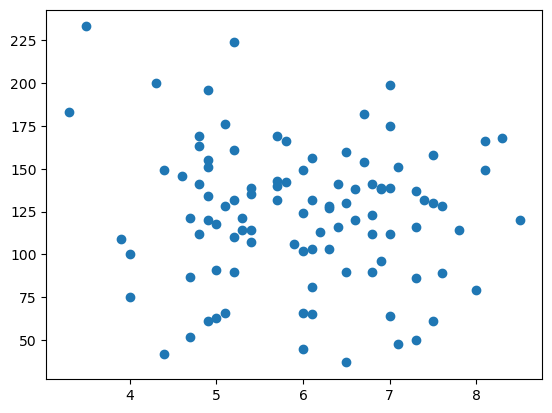

In [13]:
# stntax --> plt.scatter(data['col1'],data['col2'],c = data[col3])  
#                       x axis        y axis        color

plt.scatter(df['cgpa'], df['iq'])



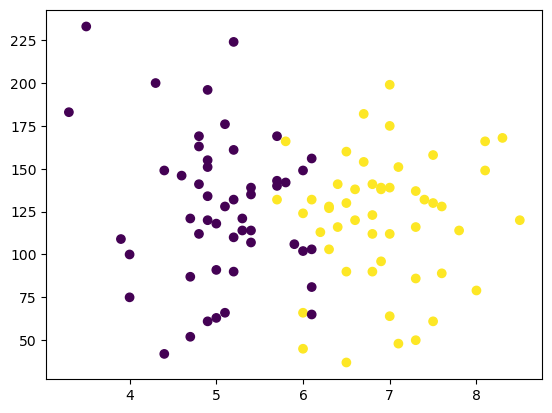

In [14]:
plt.scatter(df['cgpa'], df['iq'] , c = df['placement'])

# Extract input and output cols

In [15]:
df.head(2)

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0


In [16]:
x = df.iloc[ : ,0 : 2]

In [17]:
x.head()

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0


In [18]:
y = df.iloc[: ,-1]

In [19]:
y.head()

0    1
1    0
2    0
3    1
4    0
Name: placement, dtype: int64

In [20]:
y.shape

(100,)

In [21]:
# x--> matrix  ;  y --> vector

In [22]:
# order doesn’t matter but for learning we will split first 

 # Train test split

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
# syntax -- >.  train_test_split( input_col , output_col , train_size= 0.2)

train_test_split( x , y , train_size= 0.2)

[    cgpa     iq
 21   7.1  151.0
 36   5.7  140.0
 84   5.7  169.0
 60   6.9  139.0
 92   5.2  110.0
 56   6.1   65.0
 24   4.7  121.0
 34   4.8  163.0
 33   6.0  149.0
 4    5.8  142.0
 53   8.3  168.0
 14   6.1  103.0
 27   6.0  124.0
 98   6.3  103.0
 11   6.9  138.0
 58   8.0   79.0
 65   8.1  166.0
 63   6.3  128.0
 73   4.9   61.0
 96   4.4   42.0,
     cgpa     iq
 42   7.6   89.0
 28   5.2   90.0
 47   5.2  161.0
 19   5.2  132.0
 61   7.3  137.0
 ..   ...    ...
 40   4.9  134.0
 67   5.0  118.0
 66   6.9   96.0
 12   5.4  139.0
 17   3.3  183.0
 
 [80 rows x 2 columns],
 21    1
 36    0
 84    0
 60    1
 92    0
 56    0
 24    0
 34    0
 33    0
 4     0
 53    1
 14    0
 27    1
 98    1
 11    1
 58    1
 65    1
 63    1
 73    0
 96    0
 Name: placement, dtype: int64,
 42    1
 28    0
 47    0
 19    0
 61    1
      ..
 40    0
 67    0
 66    1
 12    0
 17    0
 Name: placement, Length: 80, dtype: int64]

In [25]:
train_x , test_x , train_y , test_y = train_test_split( x , y , train_size= 0.2)

In [26]:
train_x

,cgpa,iq
87,5.7,132.0
59,4.8,112.0
3,7.4,132.0
4,5.8,142.0
31,3.9,109.0
79,6.5,90.0
75,4.8,169.0
85,5.8,166.0
55,7.8,114.0
11,6.9,138.0


In [27]:
train_x.shape

(20, 2)

In [28]:
test_x.shape

(80, 2)

 ## see here we little bit messed up -- train was 80% , so now we will reverse the variable order 

In [29]:
test_x , train_x , test_y , train_y  = train_test_split( x , y , train_size= 0.2)

In [30]:
test_x.shape

(20, 2)

In [31]:
#  now we are on right path 

train_x.shape

(80, 2)

In [32]:
train_y.shape

(80,)

In [33]:
test_x.shape

(20, 2)

In [34]:
train_y.shape

(80,)

In [35]:
test_y.shape

(20,)

In [36]:
train_y

23    0
14    0
75    0
9     0
10    1
     ..
77    1
61    1
81    0
28    0
64    1
Name: placement, Length: 80, dtype: int64

In [37]:
train_x

,cgpa,iq
23,4.7,87.0
14,6.1,103.0
75,4.8,169.0
9,5.1,66.0
10,6.0,45.0
...,...,...
77,7.3,50.0
61,7.3,137.0
81,5.4,107.0
28,5.2,90.0


 # Scale the values

In [42]:
from sklearn.preprocessing import StandardScaler 

In [43]:
scaler = StandardScaler ()

In [44]:
train_x.head()

,cgpa,iq
23,4.7,87.0
14,6.1,103.0
75,4.8,169.0
9,5.1,66.0
10,6.0,45.0


In [45]:
train_x = scaler.fit_transform(train_x)

In [48]:
train_x.shape

(80, 2)

In [49]:
train_x

array([[-1.08509341, -0.80070958],
       [ 0.10989638, -0.42760864],
       [-0.999737  ,  1.11143269],
       [-0.74366776, -1.29040455],
       [ 0.02453997, -1.78009952],
       [ 0.87810411,  1.81099694],
       [-1.08509341, -1.61686786],
       [ 0.02453997, -1.29040455],
       [-0.57295493, -0.17110175],
       [ 0.10989638, -0.94062242],
       [-0.91438058,  1.74104051],
       [-0.999737  ,  0.45850607],
       [ 0.45132204, -0.73075315],
       [ 1.30488618, -1.40699859],
       [-1.42651907,  1.83431575],
       [ 1.98773749,  1.08811389],
       [ 1.30488618,  0.20199918],
       [ 0.28060921,  0.13204275],
       [-0.82902417, -1.36036097],
       [-1.34116265,  0.64505653],
       [ 0.45132204,  0.20199918],
       [-2.2800832 ,  1.43789601],
       [ 0.62203487,  1.4145772 ],
       [-1.34116265, -1.85005594],
       [-1.68258831, -0.49756507],
       [-0.91438058, -0.03118891],
       [ 0.70739128,  0.45850607],
       [ 0.70739128,  0.03876752],
       [ 0.02453997,

In [50]:
test_x = scaler.transform(test_x)

In [51]:
test_x

array([[ 0.36596562, -0.12446414],
       [-0.82902417, -0.70743434],
       [ 0.70739128, -0.73075315],
       [ 0.62203487,  0.76165057],
       [-0.23152927,  0.50514368],
       [-0.14617286,  1.04147627],
       [-0.74366776,  0.15536156],
       [ 0.10989638,  0.24863679],
       [-0.48759851,  0.41186845],
       [-0.57295493, -0.0078701 ],
       [-0.91438058,  0.69169415],
       [ 1.81702466,  0.64505653],
       [ 0.45132204,  0.90156342],
       [-0.91438058,  0.29527441],
       [-0.999737  , -0.21773937],
       [ 0.53667845, -0.03118891],
       [ 0.79274769,  0.38854964],
       [ 1.56095542, -0.17110175],
       [-0.65831134,  0.92488223],
       [ 1.21952976,  0.24863679]])

In [52]:
#  now scalig done

 # Train the model

In [53]:
from sklearn.linear_model import LogisticRegression

In [54]:
#  creating object of class 

lr = LogisticRegression()

In [55]:
# syntax -->  LogisticRegression.fit(train_input , train_output)

lr.fit(train_x , train_y)

LogisticRegression()

 # Evaluate the model/model selection

In [56]:
lr.predict(test_x)

array([1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1])

In [57]:
test_y

13    1
25    0
35    1
74    1
6     0
85    1
86    0
71    1
12    0
2     0
89    0
37    1
38    1
40    0
59    0
20    1
11    1
55    1
47    0
3     1
Name: placement, dtype: int64

In [58]:
predict_y = lr.predict(test_x)

In [59]:
predict_y

array([1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1])

In [60]:
test_y.shape

(20,)

In [61]:
predict_y.shape

(20,)

In [62]:
#  now for compare : 

In [63]:
from sklearn.metrics import accuracy_score

In [64]:
accuracy_score(test_y , predict_y)

0.95

In [65]:
# / this shows 95 correct outof 100


In [66]:
from mlxtend.plotting import plot_decision_regions

ModuleNotFoundError: No module named 'mlxtend'

In [67]:
!pip install mlxtend

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.1 MB/s eta 0:00:00a 0:00:01


In [68]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

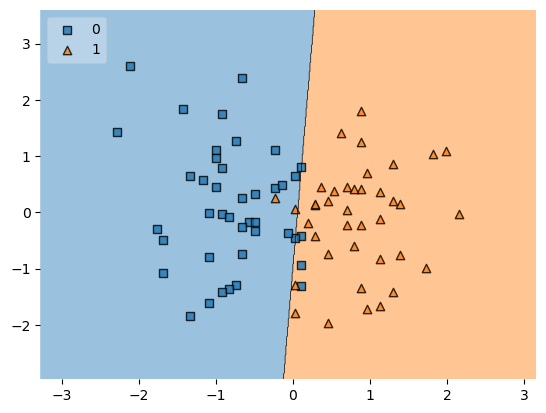

In [69]:
plot_decision_regions(train_x , train_y.values , clf= lr , legend=2)

In [70]:
train_y

23    0
14    0
75    0
9     0
10    1
     ..
77    1
61    1
81    0
28    0
64    1
Name: placement, Length: 80, dtype: int64

In [71]:
train_y.values

array([0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1])

In [72]:
type(train_y)

pandas.core.series.Series

In [73]:
type(train_y.values)

numpy.ndarray

# Deploy the model

In [74]:
import pickle

In [77]:
pickle.dump(lr,open('L-13_100_Days_Of_ML_EndToEndPracticeProject.ipynb-13Model.pkl','wb'))